# 04 · Toetsbare hypothese

**Auteurs:** _vul namen en concrete bijdragen in vóór indiening_  
**Doel:** Vóór modelleren aantonen of een praktisch betekenisvol voorspelpatroon bestaat.

Elke codecel wordt voorafgegaan door uitleg. Voer de notebooks in nummervolgorde uit
vanaf de repository-root. Resultaten moeten door het team zelf worden gecontroleerd en
geïnterpreteerd; synthetische CI-data gelden nooit als onderzoeksbewijs.

In [3]:
# Maak lokale projectimports betrouwbaar in VS Code, JupyterLab en nbconvert.
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "pyproject.toml").exists() and (path / "src").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Projectroot niet gevonden; open de map Brent als VS Code-workspace.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"Projectroot: {PROJECT_ROOT}")

Projectroot: c:\Users\brent\3ACS01\Deep Learning\CloudAI-Challenge\citi_bike\Brent


## Vooraf vastgelegd

- **H₀:** ritduur heeft dezelfde verdeling voor casual riders en members.
- **H₁ (eenzijdig):** casual riders maken typisch langere ritten.
- **α = 0,05.**
- Primair praktisch effect: verschil in mediaan met 95%-bootstrap-BI.
- Secundair: Cliff's delta; de Mann–Whitney-toets levert statistische evidentie.

Dit is associationeel, niet causaal: rijderstype kan samenhangen met route, dag en seizoen.

In [4]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.analysis.hypothesis import test_member_difference
from src.config import PROCESSED_DIR, REPORT_DIR
from src.data.sample import systematic_parquet_sample

trips = systematic_parquet_sample(
    PROCESSED_DIR / "trips.parquet", max_rows=1_000_000,
    columns=["member_casual", "duration_minutes"],
)
result = test_member_difference(trips)
print(json.dumps(result, indent=2))
REPORT_DIR.mkdir(exist_ok=True)
(REPORT_DIR / "hypothesis_result.json").write_text(json.dumps(result, indent=2))

{
  "hypothesis": "casual duration tends to be greater than member duration",
  "n_casual": 177448,
  "n_member": 822343,
  "median_casual": 15.350108333333333,
  "median_member": 9.0373,
  "median_difference": 6.312808333333333,
  "median_difference_ci95": [
    5.958086250000001,
    6.659999791666666
  ],
  "mann_whitney_u": 24010071117.0,
  "one_sided_p_value": 0.0,
  "p_value_interpretation": "below floating-point precision (reported as 0.0)",
  "cliffs_delta_casual_minus_member": 0.3534984793449935,
  "note": "p-value uses capped deterministic samples; effect sizes use all rows or pair subsampling"
}


613

## Visualisatie van effect, niet alleen p-waarde

We tonen medianen en het bootstrapinterval van hun verschil.

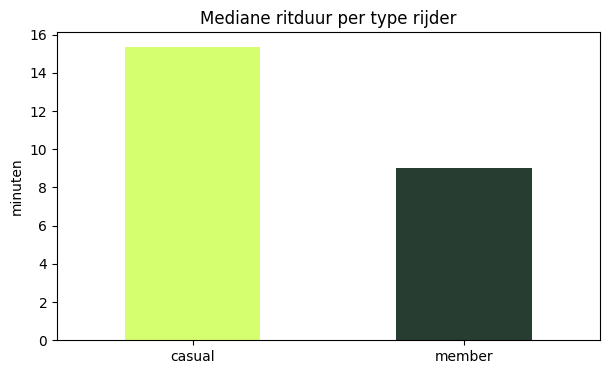

95%-BI mediaanverschil casual − member: [5.958086250000001, 6.659999791666666]


In [5]:
medians = trips.groupby("member_casual").duration_minutes.median().sort_index()
ax = medians.plot.bar(color=["#d6ff70", "#283d32"], figsize=(7, 4))
ax.set(title="Mediane ritduur per type rijder", xlabel="", ylabel="minuten")
plt.xticks(rotation=0)
plt.show()
print("95%-BI mediaanverschil casual − member:", result["median_difference_ci95"])

## Beslisregel en conclusie

Verwerp H₀ alleen wanneer p < 0,05 én bespreek of effectgrootte/BI praktisch relevant
zijn. Een klein effect met een minuscule p-waarde is bij miljoenen ritten geen sterke
productreden. Noteer hier na uitvoering de concrete conclusie en hoe dit de feature
`member_casual` motiveert.